# Supporting Figure S3

![Full Figure](../figures/suppS3_FULL.png)

## Code for Supporting Figure S3: trained-session thresholds

**Goal:** Display the 21-session hit-rate and 7-session violation-rate thresholds used to define each animal’s trained analysis window.

Rolling rates and crossing sessions come from [`scripts/prepare_full_pipeline.py`](../scripts/prepare_full_pipeline.py) via `load_rolling_performance()` and `load_threshold_sessions()`. The notebook only visualizes those outputs.

| Input | Content |
|---|---|
| Rolling performance | 21-session hit and 7-session violation rolling means (`training_stage > 3`) |
| Threshold sessions | Last low→high crossing at hit 0.725 / violation 0.5; violation end only for W065, W080, W083, W088 |

**Outputs:** `figures/suppS3_trained_thresholding.png`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from violations_glm.config import HIT_COLOR, VIOLATION_COLOR
from violations_glm.io import load_rolling_performance, load_threshold_sessions
from violations_glm.plotting import configure_publication_dpi, save_figure

configure_publication_dpi()
sns.set_context("talk")

## Trained analysis windows

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS3_trained_thresholding.png')

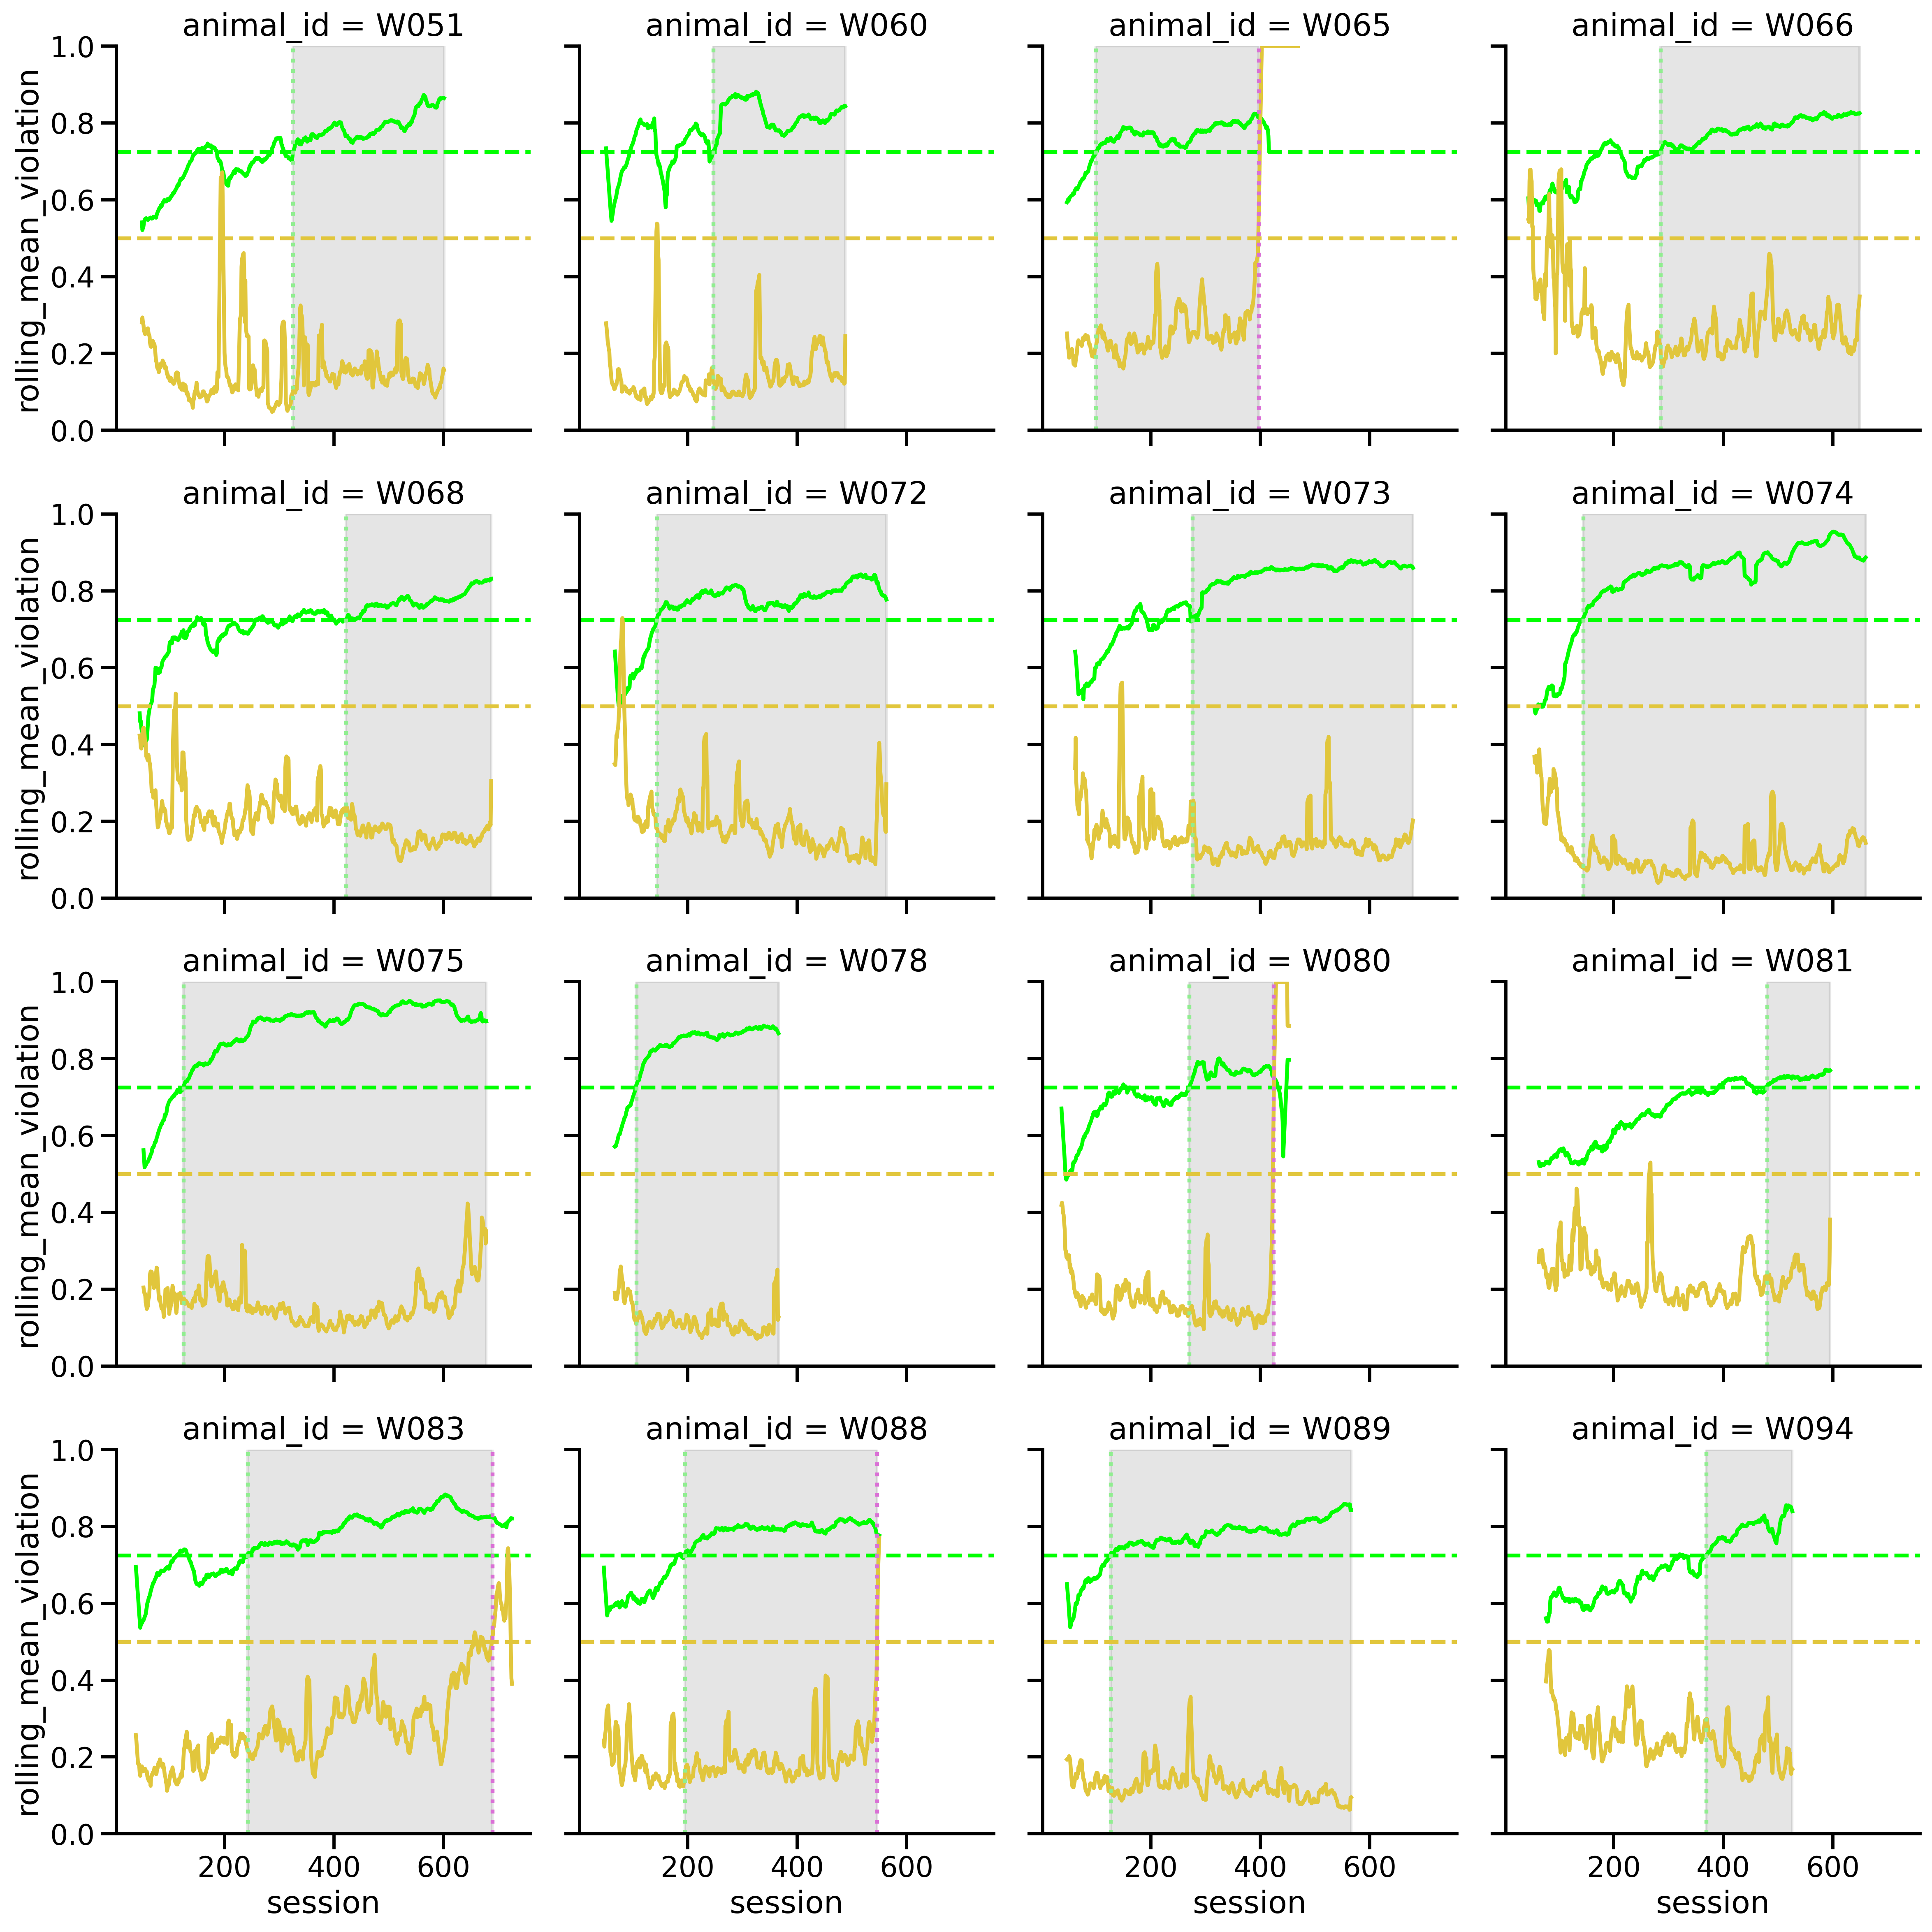

In [2]:
hit_viol_rolling_means = load_rolling_performance()
hit_viol_threshold_df = load_threshold_sessions().reset_index(drop=True)

g = sns.FacetGrid(
    data=hit_viol_rolling_means.query("training_stage > 3"),
    col="animal_id",
    col_wrap=4,
    height=4,
    ylim=(0, 1),
)
g.map(sns.lineplot, "session", "rolling_mean_hit", color=HIT_COLOR)
g.map(plt.axhline, y=0.725, color=HIT_COLOR, linestyle="--")
g.map(sns.lineplot, "session", "rolling_mean_violation", color=VIOLATION_COLOR)
g.map(plt.axhline, y=0.5, color=VIOLATION_COLOR, linestyle="--")

for ii, ax in enumerate(g.axes.flat):
    hit_threshold = hit_viol_threshold_df["hit_threshold"][ii]
    violation_threshold = hit_viol_threshold_df["violation_threshold"][ii]
    animal_id = hit_viol_threshold_df["animal_id"][ii]

    if animal_id in ["W061", "W062"]:
        continue

    ax.axvline(x=hit_threshold, color="lightgreen", linestyle=":")
    if pd.notna(violation_threshold):
        ax.axvline(x=violation_threshold, color="orchid", linestyle=":")
        ax.fill_betweenx(
            ax.get_ylim(), hit_threshold, violation_threshold, color="grey", alpha=0.2
        )
    else:
        max_x_value = hit_viol_rolling_means.query(
            "animal_id == @animal_id"
        ).session.max()
        ax.fill_betweenx(
            ax.get_ylim(), hit_threshold, max_x_value, color="grey", alpha=0.2
        )

save_figure(g.figure, "suppS3_trained_thresholding")